<a href="https://colab.research.google.com/github/samodamarasinghe/CRM_CW1/blob/main/CRM_CW1_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# Install once in Colab (skip if your environment already has these).
%pip -q install yfinance pandas numpy scipy scikit-learn matplotlib pyarrow lxml beautifulsoup4 requests openpyxl

In [5]:
import sys, json, time, hashlib, warnings, platform
from io import StringIO
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yfinance as yf
import scipy
import sklearn
import matplotlib.pyplot as plt
import requests
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from IPython.display import display

In [6]:
OUTPUT = Path('CWK1_outputs')
FIGS = OUTPUT / 'figures'
OUTPUT.mkdir(exist_ok=True); FIGS.mkdir(exist_ok=True)
START, END = '2021-01-01', '2025-01-01'  # END exclusive
RUN_UTC = datetime.now(timezone.utc).isoformat()
OBS_START = pd.Timestamp(START)
OBS_END = pd.Timestamp(END)
SEED = 42
# Thresholds are transparent analysis choices; justify them in your report.
MIN_WEEKLY_COVERAGE = 0.90
MIN_LAST_SESSIONS = 80   # 20 for history + last 60 for RFM
BATCH_SIZE = 20
USE_CACHED_SNAPSHOT = False   # Change to True when re-running a saved historical snapshot
print('Run UTC:', RUN_UTC)
print('Versions:', {'python': platform.python_version(), 'pandas': pd.__version__,
                    'numpy': np.__version__, 'yfinance': yf.__version__,
                    'scipy': scipy.__version__, 'sklearn': sklearn.__version__})

Run UTC: 2026-11-24T08:02:16.876517+00:00
Versions: {'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'scipy': '1.16.3', 'sklearn': '1.6.1'}


1.1 — Ticker selection and data acquisition

In [7]:
# Wikipedia URL containing the S&P 500 company list
WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Define the path to save the S&P 500 constituents dataset
const_path = OUTPUT / 'constituents.csv'

# Check whether a previously saved dataset should be used
if USE_CACHED_SNAPSHOT and const_path.exists():

    # Load the existing S&P 500 constituents dataset
    constituents = pd.read_csv(const_path)

else:
    # Request the S&P 500 company list from Wikipedia
    response = requests.get(
        WIKI_URL,
        headers={'User-Agent': 'Mozilla/5.0 (educational research)'},
        timeout=40
    )

In [10]:
# Check whether the request was successful
response.raise_for_status()

# Extract all HTML tables from the Wikipedia webpage
tables = pd.read_html(StringIO(response.text))

# Find the table containing stock symbols and GICS sectors
candidates = [
    t for t in tables
    if {'Symbol', 'GICS Sector'}.issubset(set(t.columns))
]

# Display an error if the required table is not found
if not candidates:
    raise ValueError(
        'Wikipedia table layout changed; inspect columns and choose the S&P 500 table.'
    )

In [13]:
# Select the S&P 500 constituents table
constituents = candidates[0].copy()

# Convert ticker symbols into Yahoo Finance format
# Example: BRK.B becomes BRK-B
constituents['YahooTicker'] = (
    constituents['Symbol']
    .astype(str)
    .str.replace('.', '-', regex=False)
)

# Record the date and time of data retrieval
constituents['RetrievalUTC'] = RUN_UTC

# Remove duplicate stock ticker symbols
constituents = constituents.drop_duplicates('YahooTicker')

# Save the cleaned S&P 500 constituent list as a CSV file
constituents.to_csv(const_path, index=False)

In [14]:
# Check whether the required columns exist in the dataset
assert {'YahooTicker', 'GICS Sector'}.issubset(constituents.columns)

# Extract unique S&P 500 ticker symbols
# Remove missing values and convert symbols to strings
TICKERS = constituents['YahooTicker'].dropna().astype(str).unique().tolist()

# Include the S&P 500 market benchmark (^GSPC) with the stock tickers
ALL_TICKERS = TICKERS + ['^GSPC']

# Display the total number of S&P 500 tickers and benchmark
print('Current constituents downloaded:', len(TICKERS), '| Benchmark: ^GSPC')

# Display the first five companies with their symbols, names, and sectors
display(constituents[['Symbol', 'YahooTicker', 'Security', 'GICS Sector']].head())

Current constituents downloaded: 503 | Benchmark: ^GSPC


,Symbol,YahooTicker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [15]:
def standardize_yahoo_batch(download, tickers):
    """Convert yfinance 'group_by=ticker' output into one long-format data snapshot."""
    if download is None or download.empty:
        return pd.DataFrame(), list(tickers)
    records, missing = [], []
    for ticker in tickers:
        if isinstance(download.columns, pd.MultiIndex):
            if ticker in download.columns.get_level_values(0):
                one = download[ticker].copy()
            elif ticker in download.columns.get_level_values(1):
                one = download.xs(ticker, axis=1, level=1).copy()
            else:
                missing.append(ticker); continue
        else:
            if len(tickers) != 1:
                missing.append(ticker); continue
            one = download.copy()
        if not {'Close','Volume'}.issubset(one.columns):
            missing.append(ticker); continue
        # yfinance sometimes returns named columns with all NaNs for a failed symbol.
        if one[['Close','Volume']].notna().sum().sum() == 0:
            missing.append(ticker); continue
        one = one.reset_index()
        date_col = 'Date' if 'Date' in one.columns else one.columns[0]
        one = one.rename(columns={date_col: 'Date'})
        one['Date'] = pd.to_datetime(one['Date'], utc=True).dt.tz_convert(None).dt.normalize()
        for col in ['Adj Close','Dividends','Stock Splits']:
            if col not in one.columns:
                one[col] = np.nan if col == 'Adj Close' else 0.0
        one['Ticker'] = ticker
        records.append(one[['Date','Ticker','Close','Adj Close','Volume','Dividends','Stock Splits']])
    return (pd.concat(records, ignore_index=True) if records else pd.DataFrame()), missing

In [16]:
# Define a function to download daily stock data from Yahoo Finance
def download_chunk(tickers, retries=3):

    # Store the most recent download error
    last_error = None

    # Retry the download if an error occurs
    for attempt in range(retries):
        try:
            # Download daily stock prices, adjusted prices, volume,
            # dividends and stock split information
            raw = yf.download(
                tickers=tickers,
                start=START,
                end=END,
                interval='1d',
                auto_adjust=False,
                actions=True,
                group_by='ticker',
                multi_level_index=True,
                progress=False,
                threads=False,
                timeout=40
            )

            # Convert downloaded data into a standard format
            # Identify any missing ticker symbols
            result, missing = standardize_yahoo_batch(raw, tickers)

            # Return the data if the download is successful
            if not result.empty:
                return result, missing, None

            # Record an error if the response is empty
            last_error = 'Empty response'

        except Exception as exc:
            # Store the error message if the download fails
            last_error = repr(exc)

        # Wait before retrying the download
        time.sleep(2 * (attempt + 1))

    # Return an empty DataFrame if all attempts fail
    return pd.DataFrame(), list(tickers), last_error

In [17]:
# Define file paths for saving downloaded stock data and download errors
raw_path = OUTPUT / 'daily_snapshot.parquet'
log_path = OUTPUT / 'download_log.csv'

# Check whether previously downloaded data is available
if USE_CACHED_SNAPSHOT and raw_path.exists() and log_path.exists():

    # Load the previously saved daily stock dataset
    raw_daily = pd.read_parquet(raw_path)

    # Load the previously saved download error log
    download_log = pd.read_csv(log_path)

else:
    # Create lists to store downloaded batches and failed tickers
    batches, failures = [], []

    # Download the stock data in smaller batches
    for i in range(0, len(ALL_TICKERS), BATCH_SIZE):

        # Select a group of ticker symbols for the current batch
        tickers_batch = ALL_TICKERS[i:i+BATCH_SIZE]

        # Download stock data and identify missing tickers
        part, missing, error = download_chunk(tickers_batch)

        # Store successfully downloaded stock data
        if not part.empty:
            batches.append(part)

        # Record missing ticker symbols and their download errors
        for t in missing:
            failures.append({
                'Ticker': t,
                'BatchNumber': i//BATCH_SIZE+1,
                'Reason': error or 'Missing/empty ticker payload'
            })

        # Display the number of requested and missing tickers
        print(
            f'Batch {1+i//BATCH_SIZE}: '
            f'requested {len(tickers_batch)}, missing {len(missing)}'
        )

        # Wait before downloading the next batch
        time.sleep(1)

Batch 1: requested 20, missing 0
Batch 2: requested 20, missing 0
Batch 3: requested 20, missing 0
Batch 4: requested 20, missing 0
Batch 5: requested 20, missing 0
Batch 6: requested 20, missing 0
Batch 7: requested 20, missing 0
Batch 8: requested 20, missing 0
Batch 9: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 10: requested 20, missing 1
Batch 11: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 12: requested 20, missing 1
Batch 13: requested 20, missing 0
Batch 14: requested 20, missing 0
Batch 15: requested 20, missing 0
Batch 16: requested 20, missing 0
Batch 17: requested 20, missing 0
Batch 18: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 19: requested 20, missing 1
Batch 20: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 21: requested 20, missing 1
Batch 22: requested 20, missing 0
Batch 23: requested 20, missing 0


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Batch 24: requested 20, missing 1
Batch 25: requested 20, missing 0
Batch 26: requested 4, missing 0


In [20]:
# Combine and save raw daily stock returns and download log from memory
if 'raw_daily' not in globals():
    raw_daily = pd.concat(batches, ignore_index=True) if batches else pd.DataFrame()
    raw_daily.to_parquet(raw_path, index=False)

if 'download_log' not in globals():
    download_log = pd.DataFrame(failures) if failures else pd.DataFrame(columns=['Ticker', 'BatchNumber', 'Reason'])
    download_log.to_csv(log_path, index=False)

print('Rows:', len(raw_daily), '| tickers with any records:', raw_daily.Ticker.nunique())
print('Failed/missing tickers:', download_log.Ticker.nunique())
display(download_log.head())

Rows: 501495 | tickers with any records: 499
Failed/missing tickers: 5


,Ticker,BatchNumber,Reason
0,FDXF,10,Missing/empty ticker payload
1,HONA,12,Missing/empty ticker payload
2,Q,19,Missing/empty ticker payload
3,SNDK,21,Missing/empty ticker payload
4,VYLR,24,Missing/empty ticker payload


1.2 — Data validation and alignment

In [21]:
# Convert the Date column into datetime format and remove time information
raw_daily['Date'] = pd.to_datetime(raw_daily['Date']).dt.normalize()

# Sort the dataset by ticker symbol and date
raw_daily = raw_daily.sort_values(['Ticker', 'Date']).copy()

# Identify duplicate records with the same ticker and date
dup_mask = raw_daily.duplicated(['Ticker', 'Date'], keep=False)

# Store duplicate records for further investigation
duplicate_evidence = raw_daily.loc[dup_mask].copy()

# Save duplicate records to a CSV file
duplicate_evidence.to_csv(
    OUTPUT / 'duplicate_date_evidence.csv',
    index=False
)

In [22]:
# Create a set to store ticker symbols with conflicting duplicate records
# Only identical duplicates are removed; conflicting records cause exclusion
conflicts = set()

# Check whether duplicate records exist
if len(duplicate_evidence):

    # Examine duplicate records for each stock ticker
    for ticker, part in duplicate_evidence.groupby('Ticker'):

        # Check whether duplicate dates contain different
        # Close, Adjusted Close or Volume values
        differing = part.groupby('Date')[
            ['Close', 'Adj Close', 'Volume']
        ].nunique(dropna=False).gt(1).any(axis=1)


In [23]:
# Create a set to store ticker symbols with conflicting duplicate records
# Only identical duplicates are removed; conflicting records cause exclusion
conflicts = set()

# Check whether duplicate records exist
if len(duplicate_evidence) > 0:
    # Examine duplicate records for each stock ticker
    for ticker, part in duplicate_evidence.groupby('Ticker'):
        # Check whether duplicate dates contain different
        # Close, Adjusted Close or Volume values
        differing = part.groupby('Date')[['Close', 'Adj Close', 'Volume']].nunique(dropna=False).gt(1).any(axis=1)

        # Record tickers containing conflicting duplicate values
        if differing.any():
            conflicts.add(ticker)

    # Remove completely identical duplicate records
    raw_daily = raw_daily.drop_duplicates(keep='first')

# Keep the first record for each ticker and date
raw_daily = raw_daily.drop_duplicates(
    ['Ticker', 'Date'],
    keep='first'
)

In [24]:
# Convert Close, Adjusted Close and Volume columns into numeric values
# Invalid values are converted to NaN
raw_daily[['Close', 'Adj Close', 'Volume']] = raw_daily[
    ['Close', 'Adj Close', 'Volume']
].apply(pd.to_numeric, errors='coerce')

# Identify missing or nonpositive closing prices
raw_daily['BadClose'] = (
    raw_daily['Close'].isna() |
    (raw_daily['Close'] <= 0)
)

# Identify missing or nonpositive adjusted closing prices
raw_daily['BadAdj'] = (
    raw_daily['Adj Close'].isna() |
    (raw_daily['Adj Close'] <= 0)
)

In [25]:
# Identify missing or nonpositive trading volumes
raw_daily['BadVolume'] = (
    raw_daily['Volume'].isna() |
    (raw_daily['Volume'] <= 0)
)

# Calculate the ratio between adjusted closing price and closing price
raw_daily['AdjustmentRatio'] = (
    raw_daily['Adj Close'] / raw_daily['Close']
)

# Calculate the absolute percentage change in the adjustment ratio
# Separately for each stock ticker
raw_daily['AdjustmentChange'] = raw_daily.groupby(
    'Ticker'
)['AdjustmentRatio'].pct_change(fill_method=None).abs()

In [26]:
# Flag possible corporate actions requiring further investigation
# A flag is raised if the adjustment ratio changes by more than 10%
# or if a stock split is recorded
raw_daily['CorporateActionReviewFlag'] = (
    (raw_daily['AdjustmentChange'] > 0.10) |
    (raw_daily['Stock Splits'].fillna(0) != 0)
)

In [27]:
validation_summary = raw_daily.groupby('Ticker').agg(
    DailyRows=('Date','size'), FirstDate=('Date','min'), LastDate=('Date','max'),
    MissingClose=('BadClose','sum'), MissingAdj=('BadAdj','sum'),
    ZeroOrMissingVolume=('BadVolume','sum'), CorporateActionFlags=('CorporateActionReviewFlag','sum'))
validation_summary.to_csv(OUTPUT/'validation_summary.csv')
# An explicit table of anomalous days to inspect before drawing conclusions.
raw_daily.loc[raw_daily['BadClose']|raw_daily['BadAdj']|raw_daily['BadVolume']|
              raw_daily['CorporateActionReviewFlag'],
              ['Ticker','Date','Close','Adj Close','Volume','AdjustmentRatio','Stock Splits',
               'BadClose','BadAdj','BadVolume','CorporateActionReviewFlag']].to_csv(
                   OUTPUT/'daily_validation_flags.csv',index=False)
display(validation_summary.describe(include='all'))
print('Conflicting duplicate tickers:', sorted(conflicts)[:20], 'count=',len(conflicts))

,DailyRows,FirstDate,LastDate,MissingClose,MissingAdj,ZeroOrMissingVolume,CorporateActionFlags
count,499.0,499,499,499.000000,499.000000,499.000000,499.000000
mean,1005.0,2021-01-04 00:00:00.000000256,2024-12-31 00:00:00,8.388778,8.388778,9.294589,0.122244
min,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
50%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
75%,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,0.000000,0.000000,0.000000,0.000000
max,1005.0,2021-01-04 00:00:00,2024-12-31 00:00:00,812.000000,812.000000,812.000000,3.000000
std,0.0,NaN,NaN,74.387682,74.387682,76.680761,0.379026


Conflicting duplicate tickers: [] count= 0


In [28]:
# Remove invalid values without forward or backward filling
clean_adj = raw_daily['Adj Close'].where(~raw_daily['BadAdj'])
clean_close = raw_daily['Close'].where(~raw_daily['BadClose'])
clean_vol = raw_daily['Volume'].where(~raw_daily['BadVolume'])

# Create a DataFrame containing valid prices and volume
working = raw_daily.assign(
    ValidAdj=clean_adj,
    ValidClose=clean_close,
    ValidVolume=clean_vol
)

# Pivot data: dates as rows and tickers as columns
P_ADJ = working.pivot(index='Date', columns='Ticker', values='ValidAdj').sort_index()
P_CLOSE = working.pivot(index='Date', columns='Ticker', values='ValidClose').sort_index()
P_VOL = working.pivot(index='Date', columns='Ticker', values='ValidVolume').sort_index()

# Check benchmark availability
if '^GSPC' not in P_ADJ.columns:
    raise RuntimeError('Missing ^GSPC adjusted closing prices')

market_dates = pd.DatetimeIndex(P_ADJ['^GSPC'].dropna().index).sort_values()

if len(market_dates) < 200:
    raise RuntimeError('Benchmark history too short; investigate source/cached data')

# Align share data with benchmark trading dates
P_ADJ = P_ADJ.reindex(market_dates)
P_CLOSE = P_CLOSE.reindex(market_dates)
P_VOL = P_VOL.reindex(market_dates)

# Set the common observation date
OBSERVATION_DATE = market_dates.max()

print(
    'Benchmark sessions:', len(market_dates),
    '| last common potential observation date:', OBSERVATION_DATE.date()
)

Benchmark sessions: 1005 | last common potential observation date: 2024-12-31


1.3.1 — Mean weekly return

In [29]:
# Resample adjusted closing prices into Friday-ending weeks
WEEKLY_PRICES = P_ADJ.resample('W-FRI').last()

# Exclude incomplete first and final calendar weeks
week_starts = WEEKLY_PRICES.index - pd.Timedelta(days=4)
full_week = (week_starts >= OBS_START) & (WEEKLY_PRICES.index < OBS_END)
WEEKLY_PRICES = WEEKLY_PRICES.loc[full_week]

# Calculate weekly percentage returns without filling missing values
WEEKLY_RETURNS = WEEKLY_PRICES.pct_change(fill_method=None)
BENCHMARK_RETURNS = WEEKLY_RETURNS['^GSPC'].dropna()

# Save weekly returns
WEEKLY_RETURNS.to_csv(OUTPUT/'weekly_returns.csv', index_label='WeekEndingFriday')

print('Calendar weeks:', len(WEEKLY_PRICES), '| benchmark return weeks:', len(BENCHMARK_RETURNS))

# Validate Friday week labels and missing-value handling
assert (WEEKLY_RETURNS.index.dayofweek == 4).all(), 'Week labels must be Fridays'

# Boundary safety: a missing intermediate week does not generate a multiweek return
assert pd.Series([100., np.nan, 121.]).pct_change(fill_method=None).isna().iloc[2]

Calendar weeks: 208 | benchmark return weeks: 207


1.3.2 — Weekly beta

In [30]:
# Store weekly return and beta results
records = []
bench_weeks = len(BENCHMARK_RETURNS)

for ticker in TICKERS:
    if ticker not in WEEKLY_RETURNS:
        records.append({
            'Ticker': ticker,
            'MeanWeeklyReturn': np.nan,
            'WeeklyBeta': np.nan,
            'AlignedWeeks': 0
        })
        continue

    # Align share and benchmark weekly returns
    aligned = pd.concat({
        'Share': WEEKLY_RETURNS[ticker],
        'Benchmark': WEEKLY_RETURNS['^GSPC']
    }, axis=1).dropna()

    # Calculate benchmark variance
    var = aligned['Benchmark'].var() if len(aligned) > 1 else np.nan

    # Calculate mean weekly return and beta
    records.append({
        'Ticker': ticker,
        'MeanWeeklyReturn': aligned['Share'].mean() if len(aligned) else np.nan,
        'WeeklyBeta': aligned['Share'].cov(aligned['Benchmark']) / var
            if pd.notna(var) and var > 0 else np.nan,
        'AlignedWeeks': len(aligned)
    })

# Create and save the risk-return feature table
RISK_ALL = pd.DataFrame(records).set_index('Ticker')
RISK_ALL.to_csv(OUTPUT / 'risk_return_features_all.csv')

display(RISK_ALL.sort_values('AlignedWeeks', ascending=False).head())

,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
Ticker,,,
ZTS,0.000763,0.979783,207
MMM,0.001142,0.869079,207
AOS,0.001991,1.042805,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425366,207


1.4.1 — Recency

In [31]:
# Latest 60 trading sessions and observation date
last60 = P_VOL.index[-60:]
obs_date = last60[-1]

# High-volume day: Volume > 2 × previous 20-day average
previous20 = P_VOL.shift(1).rolling(20, min_periods=20).mean()
high_volume = P_VOL > (2 * previous20)

# Find the last high-volume event for each share
last_event_date = high_volume.apply(
    lambda x: x.index[x].max() if x.any() else pd.NaT
)
last_event_date = pd.to_datetime(last_event_date)

# Recency in calendar days
recency = (obs_date - last_event_date).dt.days

print("Shares with no high-volume event:",
      recency[recency.isna()].index.tolist()[:10], "..." if len(recency[recency.isna()]) > 10 else "")

print(recency.describe())

Shares with no high-volume event: [] 
count    499.000000
mean      20.673347
std       21.537571
min        4.000000
25%       11.000000
50%       11.000000
75%       18.000000
max      222.000000
dtype: float64


1.4.2 — Frequency

In [32]:
# Number of high-volume DAYS in the latest 60 sessions
frequency = high_volume.loc[last60].sum()

print(frequency.describe())


count    499.000000
mean       2.997996
std        1.333081
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
dtype: float64


1.4.3 — Monetary

In [33]:
# Total estimated traded value over the latest 60 sessions
monetary = (P_CLOSE * P_VOL).loc[last60].sum(min_count=60)

print(monetary.describe())

count    4.990000e+02
mean     2.860331e+12
std      6.301019e+13
min      1.297483e+09
25%      1.025172e+10
50%      1.688430e+10
75%      3.308534e+10
max      1.407578e+15
dtype: float64


In [34]:
rfm = pd.DataFrame({
    'Last_Event_Date': last_event_date,
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

print(rfm.describe())


                     Last_Event_Date     Recency   Frequency      Monetary
count                            499  499.000000  499.000000  4.990000e+02
mean   2024-12-10 07:50:22.845691392   20.673347    2.997996  2.860331e+12
min              2024-05-23 00:00:00    4.000000    0.000000  1.297483e+09
25%              2024-12-13 00:00:00   11.000000    2.000000  1.025172e+10
50%              2024-12-20 00:00:00   11.000000    3.000000  1.688430e+10
75%              2024-12-20 00:00:00   18.000000    4.000000  3.308534e+10
max              2024-12-27 00:00:00  222.000000    8.000000  1.407578e+15
std                              NaN   21.537571    1.333081  6.301019e+13


1.5 — Metric interpretation, logs and evidence

In [35]:
# to fix the NameErrors and KeyErrors
import numpy as np
import pandas as pd

In [36]:
# Create RFM_BASE from the already calculated 'rfm' DataFrame
RFM_BASE = pd.DataFrame(index=TICKERS)
RFM_BASE['R'] = recency.reindex(TICKERS)
RFM_BASE['F'] = frequency.reindex(TICKERS)
RFM_BASE['M'] = monetary.reindex(TICKERS)


In [37]:
# Set HasLast80 to True only if the ticker successfully exists in our clean price tables
valid_tickers_set = set(P_CLOSE.columns)
RFM_BASE['HasLast80'] = [t in valid_tickers_set for t in TICKERS]
RFM_BASE['LastEvent'] = last_event_date.reindex(TICKERS)
RFM_BASE['RFMReason'] = RFM_BASE['HasLast80'].map({True: 'Included', False: 'Excluded (Missing Price Data)'})

In [38]:
# Calculate the high-volume threshold and event flags
PREVIOUS20_MEAN = previous20
THRESHOLD = 2 * PREVIOUS20_MEAN
EVENT_FLAGS = high_volume

# Calculate Monetary using the latest 60 trading sessions
for ticker in TICKERS:
    if bool(RFM_BASE.loc[ticker, 'HasLast80']) and ticker in valid_tickers_set:
        close60 = P_CLOSE.loc[last60, ticker]
        volume60 = P_VOL.loc[last60, ticker]
        monetary[ticker] = float((close60 * volume60).sum())
    else:
        monetary[ticker] = np.nan

# Add Monetary to the RFM table
RFM_BASE['M'] = pd.Series(monetary)

# Create the final RFM feature table
RFM_ALL = RFM_BASE[
    ['R', 'F', 'M', 'HasLast80', 'LastEvent', 'RFMReason']
].copy()

# Save the RFM results
RFM_ALL.to_csv(OUTPUT / 'rfm_features_all.csv')

In [39]:
# Select AAPL as the worked example
sample_ticker = (
    'AAPL' if 'AAPL' in P_VOL.columns else TICKERS[0]
)

# Create a table showing high-volume event calculations
example_events = pd.DataFrame({
    'Date': market_dates,
    'Close': P_CLOSE[sample_ticker].values,
    'Volume': P_VOL[sample_ticker].values,
    'Prior20Mean': PREVIOUS20_MEAN[sample_ticker].values,
    'Threshold2x': THRESHOLD[sample_ticker].values,
    'Qualifies': EVENT_FLAGS[sample_ticker].values
})

# Calculate estimated daily traded value
example_events['EstTradedValue'] = (
    example_events['Close'] * example_events['Volume']
)

# Select the latest 60 trading sessions
example_60 = example_events.set_index('Date').loc[last60]

# Save the worked-example calculations
example_60.to_csv(
    OUTPUT / f'{sample_ticker}_last60_calculations.csv'
)
example_events.to_csv(
    OUTPUT / f'{sample_ticker}_event_evidence.csv',
    index=False
)

In [40]:
# Verify Frequency, Monetary and Recency calculations
if bool(RFM_ALL.loc[sample_ticker, 'HasLast80']):
    assert int(example_60['Qualifies'].sum()) == int(
        RFM_ALL.loc[sample_ticker, 'F']
    )

    assert np.isclose(
        example_60['EstTradedValue'].sum(),
        RFM_ALL.loc[sample_ticker, 'M']
    )

    event_dates = example_events.loc[
        example_events['Qualifies'], 'Date'
    ]

    expected_recency = (
        (OBSERVATION_DATE - event_dates.max()).days
        if not event_dates.empty else np.nan
    )

    assert (
        (pd.isna(expected_recency) and
         pd.isna(RFM_ALL.loc[sample_ticker, 'R']))
        or expected_recency == RFM_ALL.loc[sample_ticker, 'R']
    )

In [41]:
# Display observation date and worked-example results
print('Observation date:', OBSERVATION_DATE.date())
print(
    'Final 60-session window:',
    last60[0].date(), 'to', last60[-1].date()
)
print('Worked-example ticker:', sample_ticker)

display(RFM_ALL.loc[[sample_ticker]])
display(example_60.tail(10))

Observation date: 2024-12-31
Final 60-session window: 2024-10-07 to 2024-12-31
Worked-example ticker: AAPL


,R,F,M,HasLast80,LastEvent,RFMReason
AAPL,11.0,2.0,6.233034e+11,True,2024-12-20,Included


,Close,Volume,Prior20Mean,Threshold2x,Qualifies,EstTradedValue
Date,,,,,,
2024-12-17,253.479996,51356400.0,42354720.0,84709440.0,False,1.301782e+10
2024-12-18,248.050003,56774100.0,42690855.0,85381710.0,False,1.408282e+10
2024-12-19,249.789993,60882300.0,43718970.0,87437940.0,False,1.520779e+10
2024-12-20,254.490005,147495300.0,45004605.0,90009210.0,True,3.753608e+10
2024-12-23,255.270004,40858800.0,50273955.0,100547910.0,False,1.043003e+10
2024-12-24,258.200012,23234700.0,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100.0,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300.0,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500.0,46567965.0,93135930.0,False,8.967601e+09


In [42]:
# Create an inclusion and exclusion log for each share
EXCLUSIONS = []

for ticker in TICKERS:
    reasons = []

    if ticker in conflicts:
        reasons.append('Conflicting duplicate daily data')

    r = RISK_ALL.loc[ticker]
    f = RFM_ALL.loc[ticker]

    if not np.isfinite(r['MeanWeeklyReturn']) or not np.isfinite(r['WeeklyBeta']):
        reasons.append('Weekly return / beta unavailable')

    # Check weekly data coverage
    weekly_coverage = r['AlignedWeeks'] / bench_weeks if bench_weeks > 0 else 0.0

    if weekly_coverage < MIN_WEEKLY_COVERAGE:
        reasons.append(
            f"Weekly coverage {weekly_coverage:.1%} < {MIN_WEEKLY_COVERAGE:.0%}"
        )

    # Check RFM data availability
    if not bool(f['HasLast80']):
        reasons.append('Missing final 80-session RFM history')

    if pd.isna(f['R']):
        reasons.append('No valid R event / RFM excluded')

    if pd.isna(f['M']) or (pd.notna(f['M']) and f['M'] < 0):
        reasons.append('Invalid M')

    EXCLUSIONS.append({
        'Ticker': ticker,
        'Included': not bool(reasons),
        'Reasons': '; '.join(dict.fromkeys(reasons)) or 'Included'
    })

In [43]:
# Save the exclusion log and identify eligible shares
EXCLUSION_LOG = pd.DataFrame(EXCLUSIONS).set_index('Ticker')
EXCLUSION_LOG.to_csv(OUTPUT / 'share_exclusion_log.csv')

COMMON = EXCLUSION_LOG.index[EXCLUSION_LOG.Included].tolist()

if len(COMMON) < 10:
    raise ValueError(
        'Fewer than ten shared stocks passed validation; inspect exclusions before clustering'
    )

# Combine risk-return and RFM features for eligible shares
SHARE_FEATURES = RISK_ALL[
    ['MeanWeeklyReturn', 'WeeklyBeta']
].join(
    RFM_ALL[['R', 'F', 'M']],
    how='inner'
).loc[COMMON].copy()

# Add sector information and save the final feature table
sector_map = constituents.set_index('YahooTicker')['GICS Sector']
SHARE_FEATURES['Sector'] = sector_map.reindex(SHARE_FEATURES.index)

SHARE_FEATURES.to_csv(
    OUTPUT / 'share_feature_table.csv',
    index_label='Ticker'
)

# Display eligible shares, exclusion reasons and feature summaries
print('Common eligible shares:', len(COMMON), 'out of', len(TICKERS))

display(EXCLUSION_LOG['Reasons'].value_counts().head(12))

display(
    SHARE_FEATURES[
        ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']
    ].describe().T
)


Common eligible shares: 491 out of 503


,count
Reasons,
Included,491
Weekly return / beta unavailable; Weekly coverage 0.0% < 90%; Missing final 80-session RFM history; No valid R event / RFM excluded; Invalid M,5
Weekly coverage 18.8% < 90%,2
Weekly coverage 73.9% < 90%,1
Weekly coverage 51.2% < 90%,1
Weekly coverage 19.3% < 90%,1
Weekly coverage 86.0% < 90%,1
Weekly coverage 30.9% < 90%,1


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,491.0,2.895440e-03,2.698619e-03,-4.468093e-03,1.196841e-03,2.665348e-03,4.234419e-03,1.777248e-02
WeeklyBeta,491.0,9.807129e-01,4.207479e-01,5.545312e-02,6.689160e-01,9.531761e-01,1.180579e+00,3.778560e+00
R,491.0,2.043381e+01,2.128392e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.650000e+01,2.220000e+02
F,491.0,2.993890e+00,1.328634e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,491.0,3.973205e+10,1.287707e+11,1.297483e+09,1.025172e+10,1.670905e+10,3.242874e+10,1.847697e+12


Task 2 — Stock Segmentation and Sensitivity Analysis

2.1 — Feature Preparation

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

In [45]:
# Combine Task 1 risk-return and RFM results
features = RISK_ALL[
    ['MeanWeeklyReturn', 'WeeklyBeta']
].rename(columns={
    'MeanWeeklyReturn': 'Mean_Weekly_Return',
    'WeeklyBeta': 'Beta'
}).join(
    rfm[['Recency', 'Frequency', 'Monetary']],
    how='inner'
)

In [46]:
# Use the same eligible shares for both analyses
if 'COMMON' in globals():
    features = features.reindex(COMMON)

features = features.replace(
    [np.inf, -np.inf], np.nan
).dropna()

features = features[
    (features[['Recency', 'Frequency', 'Monetary']] >= 0).all(axis=1)
].copy()

raw_cols = [
    'Mean_Weekly_Return', 'Beta',
    'Recency', 'Frequency', 'Monetary'
]

In [47]:
# Skewness and outliers
raw = features[raw_cols]
q1 = raw.quantile(0.25)
q3 = raw.quantile(0.75)
iqr = q3 - q1

z = (raw - raw.mean()) / raw.std(ddof=0)

summary = pd.DataFrame({
    'skew': raw.skew(),
    'min': raw.min(),
    'median': raw.median(),
    'max': raw.max(),
    'IQR_outliers': (
        (raw < q1 - 1.5 * iqr) |
        (raw > q3 + 1.5 * iqr)
    ).sum(),
    'abs_z_over_3': (z.abs() > 3).sum()
})

In [48]:
print("Skew and outliers before transformation:")
display(summary.round(4))

Skew and outliers before transformation:


,skew,min,median,max,IQR_outliers,abs_z_over_3
Mean_Weekly_Return,0.9417,-4.500000e-03,2.700000e-03,1.780000e-02,16,6
Beta,1.2571,5.550000e-02,9.532000e-01,3.778600e+00,12,4
Recency,3.6397,4.000000e+00,1.100000e+01,2.220000e+02,111,11
Frequency,0.4201,0.000000e+00,3.000000e+00,8.000000e+00,2,5
Monetary,11.6614,1.297483e+09,1.670905e+10,1.847697e+12,47,5


In [49]:
# Compare raw and log1p skewness
skew_comparison = pd.DataFrame({
    'skew_raw': features[
        ['Recency', 'Frequency', 'Monetary']
    ].skew(),
    'skew_log1p': np.log1p(
        features[['Recency', 'Frequency', 'Monetary']]
    ).skew()
})

In [50]:
print("Skew of RFM variables, raw vs log1p:")
display(skew_comparison.round(3))

Skew of RFM variables, raw vs log1p:


,skew_raw,skew_log1p
Recency,3.640,1.572
Frequency,0.420,-0.932
Monetary,11.661,1.076


In [51]:
# Identify extreme observations
print("Shares with |z| > 3 on any raw feature:")
display(features.loc[(z.abs() > 3).any(axis=1), raw_cols])

Shares with |z| > 3 on any raw feature:


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
Ticker,,,,,
APD,0.001183,0.708584,85,1,2.662261e+10
AMZN,0.002681,1.386667,11,5,4.681770e+11
AAPL,0.003930,1.174836,11,2,6.233034e+11
APP,0.014393,2.434869,22,5,9.733950e+10
AZO,0.005274,0.758424,98,0,2.482392e+10
XYZ,-0.001554,2.504520,49,5,4.052406e+10
CVNA,0.010964,3.778560,36,3,3.836519e+10
COR,0.004373,0.548114,102,0,1.759981e+10
CB,0.003508,0.573060,102,0,2.523472e+10


In [52]:
# Apply log1p to Monetary for clustering
features['log1p_Monetary'] = np.log1p(features['Monetary'])

risk_cols = ['Mean_Weekly_Return', 'Beta']
activity_cols = ['Recency', 'Frequency', 'log1p_Monetary']

In [53]:
# Standardise separately
risk_scaled = pd.DataFrame(
    StandardScaler().fit_transform(features[risk_cols]),
    index=features.index,
    columns=risk_cols
)

activity_scaled = pd.DataFrame(
    StandardScaler().fit_transform(features[activity_cols]),
    index=features.index,
    columns=activity_cols
)

In [54]:
print("Standardised risk and return matrix:", risk_scaled.shape)
display(risk_scaled.describe().round(3))

Standardised risk and return matrix: (491, 2)


,Mean_Weekly_Return,Beta
count,491.000,491.000
mean,0.000,0.000
std,1.001,1.001
min,-2.731,-2.201
25%,-0.630,-0.742
50%,-0.085,-0.066
75%,0.497,0.476
max,5.518,6.656


In [55]:
print("Standardised trading activity matrix:", activity_scaled.shape)
display(activity_scaled.describe().round(3))

Standardised trading activity matrix: (491, 3)


,Recency,Frequency,log1p_Monetary
count,491.000,491.000,491.000
mean,-0.000,0.000,0.000
std,1.001,1.001,1.001
min,-0.773,-2.256,-2.859
25%,-0.444,-0.749,-0.674
50%,-0.444,0.005,-0.158
75%,-0.185,0.758,0.543
max,9.480,3.772,4.816


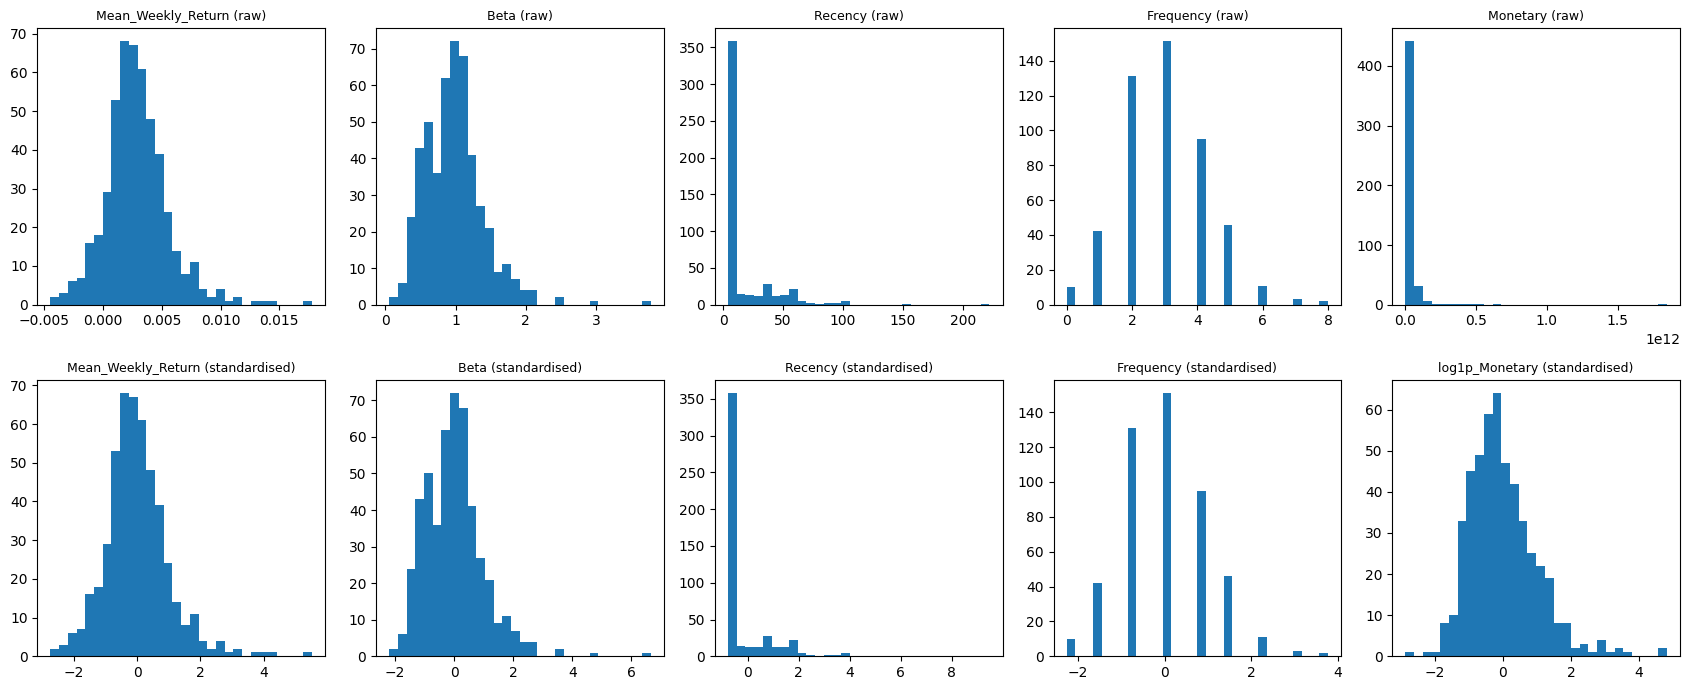

In [56]:
# Histograms: raw and standardised
fig, axes = plt.subplots(2, 5, figsize=(17, 7))

for i, column in enumerate(raw_cols):
    axes[0, i].hist(features[column], bins=30)
    axes[0, i].set_title(column + " (raw)", fontsize=9)

scaled_columns = list(risk_scaled.columns) + list(activity_scaled.columns)
scaled_data = pd.concat([risk_scaled, activity_scaled], axis=1)

for i, column in enumerate(scaled_columns):
    axes[1, i].hist(scaled_data[column], bins=30)
    axes[1, i].set_title(column + " (standardised)", fontsize=9)

plt.tight_layout()
plt.show()

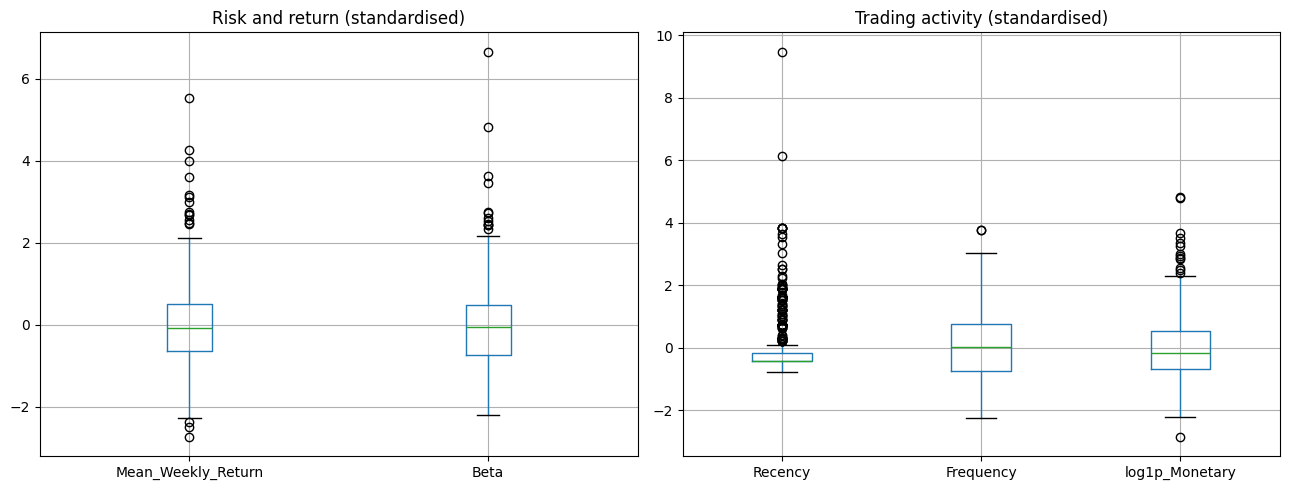

In [57]:
# Boxplots of standardised features
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

risk_scaled.boxplot(ax=axes[0])
axes[0].set_title("Risk and return (standardised)")

activity_scaled.boxplot(ax=axes[1])
axes[1].set_title("Trading activity (standardised)")

plt.tight_layout()
plt.show()

2.2 — Agglomerative Clustering

In [58]:
# Prepare feature matrices for clustering
FEATURES = features.rename(columns={
    'Mean_Weekly_Return': 'MeanWeeklyReturn',
    'Beta': 'WeeklyBeta',
    'Recency': 'R',
    'Frequency': 'F',
    'Monetary': 'M'
}).copy()

FEATURES['LogM'] = FEATURES['log1p_Monetary']

X_risk = risk_scaled.to_numpy()
X_rfm = activity_scaled.to_numpy()

# Store clustering results
ward_results = {}
ward_labels = {}
ward_k = {}

In [59]:
# Apply Ward clustering to both feature matrices
for name, X, columns in [
    ('RiskReturn', X_risk, ['MeanWeeklyReturn', 'WeeklyBeta']),
    ('RFM', X_rfm, ['R', 'F', 'M'])
]:
    results = []

    # Compare cluster counts from 2 to 8
    for k in range(2, 9):
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(X)
        sizes = np.bincount(labels)

        results.append({
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'ClusterSizes': sorted(sizes.tolist()),
            'SmallestCluster': sizes.min()
        })

    # Display silhouette scores and cluster sizes
    ward_results[name] = pd.DataFrame(results)

    print("\nWard Clustering:", name)
    display(ward_results[name].round(3))



Ward Clustering: RiskReturn


,k,Silhouette,ClusterSizes,SmallestCluster
0,2,0.511,"[36, 455]",36
1,3,0.264,"[36, 123, 332]",36
2,4,0.296,"[36, 123, 155, 177]",36
3,5,0.324,"[36, 48, 107, 123, 177]",36
4,6,0.328,"[6, 30, 48, 107, 123, 177]",6
5,7,0.295,"[6, 30, 48, 69, 107, 108, 123]",6
6,8,0.293,"[6, 20, 30, 48, 69, 103, 107, 108]",6



Ward Clustering: RFM


,k,Silhouette,ClusterSizes,SmallestCluster
0,2,0.359,"[92, 399]",92
1,3,0.307,"[92, 147, 252]",92
2,4,0.293,"[43, 92, 147, 209]",43
3,5,0.312,"[10, 43, 82, 147, 209]",10
4,6,0.320,"[10, 20, 43, 82, 127, 209]",10
5,7,0.298,"[10, 20, 43, 66, 82, 127, 143]",10
6,8,0.305,"[10, 20, 43, 57, 66, 70, 82, 143]",10


In [60]:
# Provisional k using silhouette and cluster size
for name, X in [('RiskReturn', X_risk), ('RFM', X_rfm)]:
    candidates = ward_results[name][
        ward_results[name]['SmallestCluster'] >= 5
    ]

    if candidates.empty:
        candidates = ward_results[name]

    ward_k[name] = int(
        candidates.sort_values(
            'Silhouette', ascending=False
        ).iloc[0]['k']
    )

    ward_labels[name] = AgglomerativeClustering(
        n_clusters=ward_k[name],
        linkage='ward',
        metric='euclidean'
    ).fit_predict(X)

    print(f"{name} - Provisional selected k:", ward_k[name])

RiskReturn - Provisional selected k: 2
RFM - Provisional selected k: 2


In [61]:
# Original-unit cluster profiles
for name, columns in [
    ('RiskReturn', ['MeanWeeklyReturn', 'WeeklyBeta']),
    ('RFM', ['R', 'F', 'M'])
]:
    print(f"\n=== {name} Cluster Profiles ===")
    profile = FEATURES[columns].copy()
    profile['Cluster'] = ward_labels[name]

    display(
        profile.groupby('Cluster').agg(
            ['mean', 'median', 'count']
        ).round(3)
    )


=== RiskReturn Cluster Profiles ===


MeanWeeklyReturn              WeeklyBeta             
                    mean median count       mean median count
Cluster                                                      
0                  0.002  0.003   455      0.938  0.931   455
1                  0.009  0.008    36      1.519  1.445    36


=== RFM Cluster Profiles ===


R                   F                          M                \
           mean median count   mean median count          mean        median   
Cluster                                                                        
0        12.328   11.0   399  3.211    3.0   399  3.835661e+10  1.548218e+10   
1        55.587   53.0    92  2.054    2.0    92  4.569727e+10  2.048974e+10   

               
        count  
Cluster        
0         399  
1          92

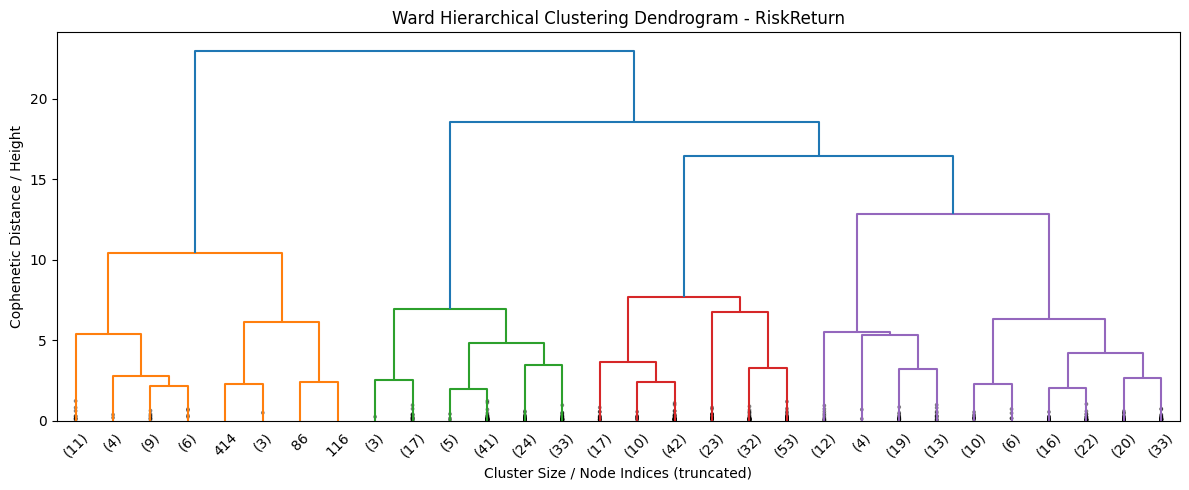

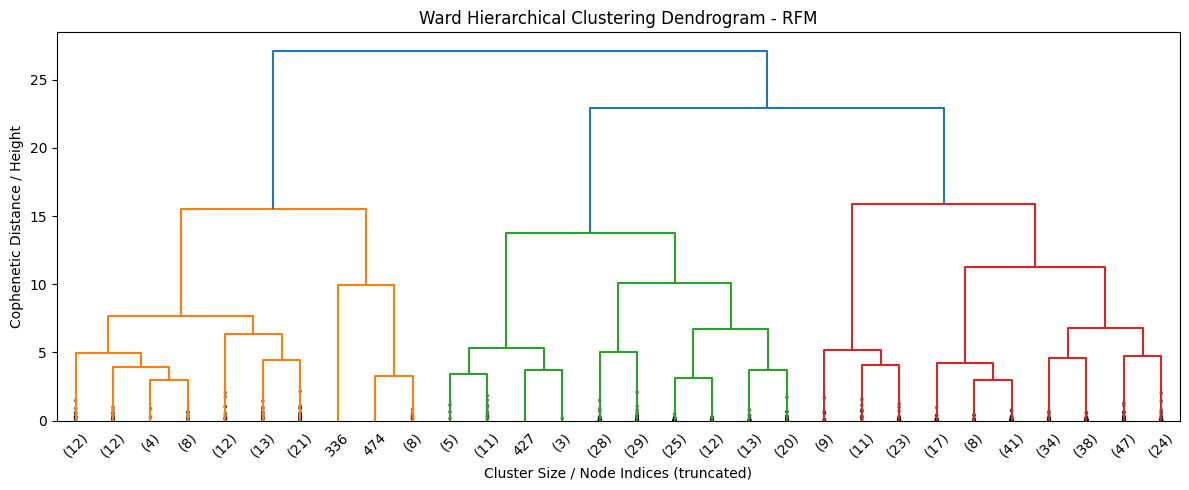

In [62]:
# Ward dendrogram
for name, X in [('RiskReturn', X_risk), ('RFM', X_rfm)]:
    Z = linkage(X, method='ward', metric='euclidean')

    plt.figure(figsize=(12, 5))
    dendrogram(
        Z,
        truncate_mode='lastp',
        p=30,
        show_contracted=True
    )
    plt.title(f"Ward Hierarchical Clustering Dendrogram - {name}")
    plt.xlabel("Cluster Size / Node Indices (truncated)")
    plt.ylabel("Cophenetic Distance / Height")
    plt.tight_layout()
    plt.show()

2.3 — K-Means Clustering

In [63]:
kmeans_results = {}
kmeans_labels = {}
kmeans_k = {}

for name, X in [
    ('RiskReturn', X_risk),
    ('RFM', X_rfm)
]:
    results = []

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=30
        )

        labels = model.fit_predict(X)
        sizes = np.bincount(labels)

        results.append({
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'Inertia': model.inertia_,
            'ClusterSizes': sorted(sizes.tolist()),
            'SmallestCluster': sizes.min()
        })

    kmeans_results[name] = pd.DataFrame(results)

    print("\nK-Means Clustering:", name)
    display(kmeans_results[name].round(3))

    # Provisional k using silhouette and cluster size
    candidates = kmeans_results[name][
        kmeans_results[name]['SmallestCluster'] >= 5
    ]

    if candidates.empty:
        candidates = kmeans_results[name]

    kmeans_k[name] = int(
        candidates.sort_values(
            'Silhouette', ascending=False
        ).iloc[0]['k']
    )

    kmeans_labels[name] = KMeans(
        n_clusters=kmeans_k[name],
        random_state=42,
        n_init=30
    ).fit_predict(X)

    print("Provisional selected k:", kmeans_k[name])


K-Means Clustering: RiskReturn


,k,Silhouette,Inertia,ClusterSizes,SmallestCluster
0,2,0.389,627.141,"[146, 345]",146
1,3,0.321,473.601,"[121, 166, 204]",121
2,4,0.323,373.915,"[37, 121, 158, 175]",37
3,5,0.309,315.455,"[7, 101, 102, 118, 163]",7
4,6,0.335,260.898,"[7, 43, 50, 105, 127, 159]",7
5,7,0.328,224.911,"[7, 41, 47, 77, 85, 103, 131]",7
6,8,0.355,192.952,"[7, 29, 40, 43, 76, 76, 80, 140]",7


Provisional selected k: 2

K-Means Clustering: RFM


,k,Silhouette,Inertia,ClusterSizes,SmallestCluster
0,2,0.424,1079.102,"[69, 422]",69
1,3,0.325,807.181,"[63, 153, 275]",63
2,4,0.341,616.031,"[61, 93, 122, 215]",61
3,5,0.358,520.538,"[11, 68, 89, 122, 201]",11
4,6,0.346,440.963,"[11, 42, 69, 106, 120, 143]",11
5,7,0.348,391.651,"[1, 15, 42, 64, 106, 119, 144]",1
6,8,0.348,346.357,"[1, 11, 19, 64, 67, 81, 106, 142]",1


Provisional selected k: 2


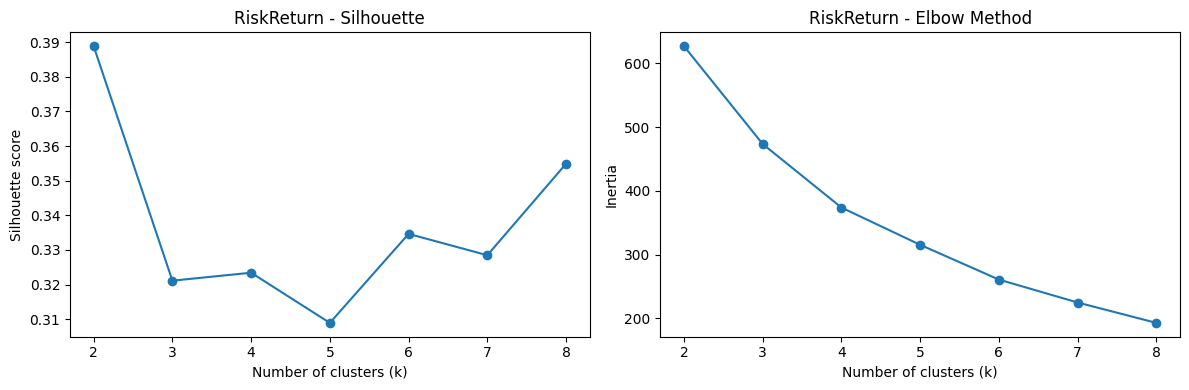

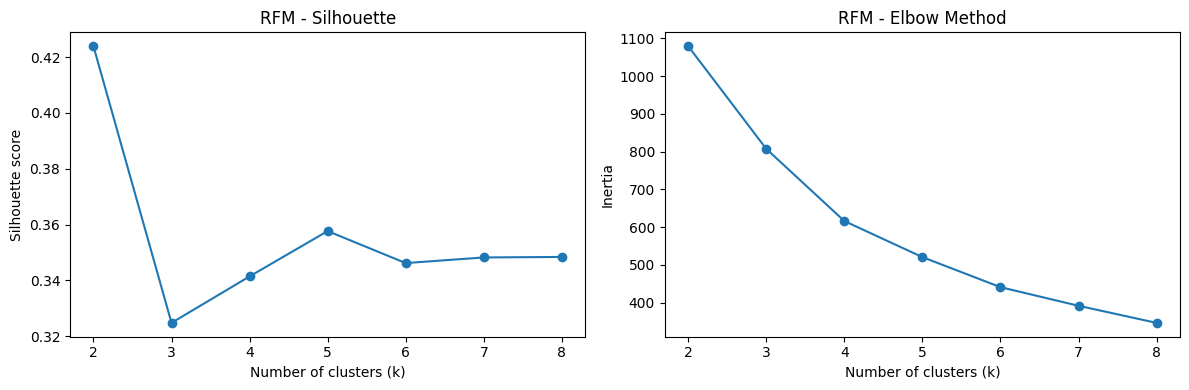

In [64]:
# Silhouette and inertia plots
for name in ['RiskReturn', 'RFM']:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        kmeans_results[name]['k'],
        kmeans_results[name]['Silhouette'],
        marker='o'
    )
    axes[0].set_title(name + " - Silhouette")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Silhouette score")

    axes[1].plot(
        kmeans_results[name]['k'],
        kmeans_results[name]['Inertia'],
        marker='o'
    )
    axes[1].set_title(name + " - Elbow Method")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("Inertia")

    plt.tight_layout()
    plt.show()

Task 2.4 — Cluster Profiles and Algorithm Comparison

In [65]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [66]:
FEATURES = features.rename(columns={
    'Mean_Weekly_Return': 'MeanWeeklyReturn',
    'Beta': 'WeeklyBeta',
    'Recency': 'R',
    'Frequency': 'F',
    'Monetary': 'M'
}).copy()

FEATURES['LogM'] = FEATURES['log1p_Monetary']

In [67]:
# Four clustering solutions
MODEL_LABELS = pd.DataFrame({
    'Ward_Risk': ward_labels['RiskReturn'],
    'KMeans_Risk': kmeans_labels['RiskReturn'],
    'Ward_RFM': ward_labels['RFM'],
    'KMeans_RFM': kmeans_labels['RFM']
}, index=FEATURES.index)

DATA = FEATURES.join(MODEL_LABELS)

DATA['MeanWeeklyReturnPct'] = (
    DATA['MeanWeeklyReturn'] * 100
)

In [68]:
# Original-unit cluster profiles
for solution in MODEL_LABELS.columns:
    print("\nCluster Profile:", solution)

    profile = DATA.groupby(solution).agg(
        Shares=('M', 'size'),
        MeanReturnPct=('MeanWeeklyReturnPct', 'mean'),
        MeanBeta=('WeeklyBeta', 'mean'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean'),
        MeanM_USD=('M', 'mean')
    )

    display(profile.round(3))


Cluster Profile: Ward_Risk


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
Ward_Risk,,,,,,
0,455,0.241,0.938,19.835,2.967,3.422715e+10
1,36,0.902,1.519,28.000,3.333,1.093078e+11



Cluster Profile: KMeans_Risk


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
KMeans_Risk,,,,,,
0,345,0.183,0.818,19.458,2.922,2.183804e+10
1,146,0.541,1.366,22.740,3.164,8.201583e+10



Cluster Profile: Ward_RFM


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
Ward_RFM,,,,,,
0,399,0.289,0.974,12.328,3.211,3.835661e+10
1,92,0.293,1.009,55.587,2.054,4.569727e+10



Cluster Profile: KMeans_RFM


,Shares,MeanReturnPct,MeanBeta,MeanR,MeanF,MeanM_USD
KMeans_RFM,,,,,,
0,422,0.287,0.976,13.450,3.187,3.271447e+10
1,69,0.308,1.012,63.145,1.812,8.265111e+10


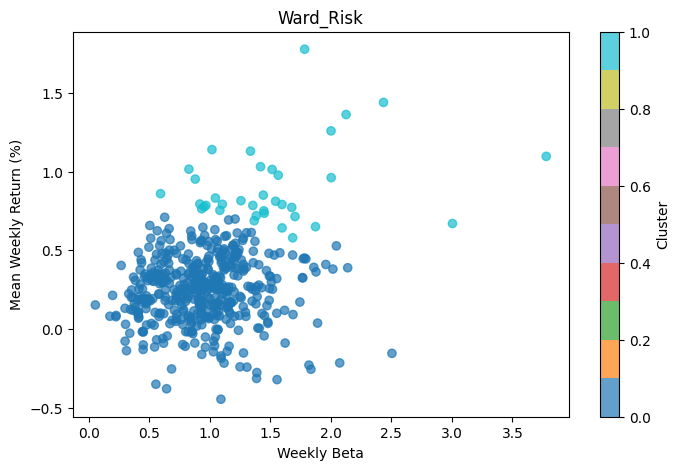

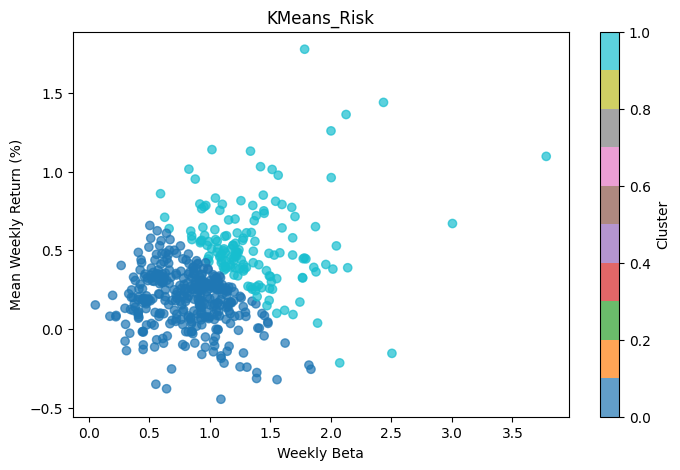

In [69]:
# Risk-return scatter plots
for solution in ['Ward_Risk', 'KMeans_Risk']:
    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        DATA['WeeklyBeta'],
        DATA['MeanWeeklyReturnPct'],
        c=DATA[solution],
        cmap='tab10',
        alpha=0.7
    )

    plt.xlabel('Weekly Beta')
    plt.ylabel('Mean Weekly Return (%)')
    plt.title(solution)
    plt.colorbar(scatter, label='Cluster')
    plt.show()

PCA explained variance: [0.456 0.339]


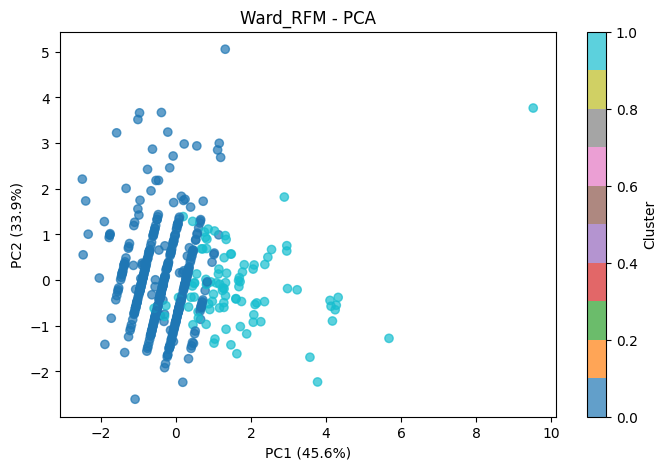

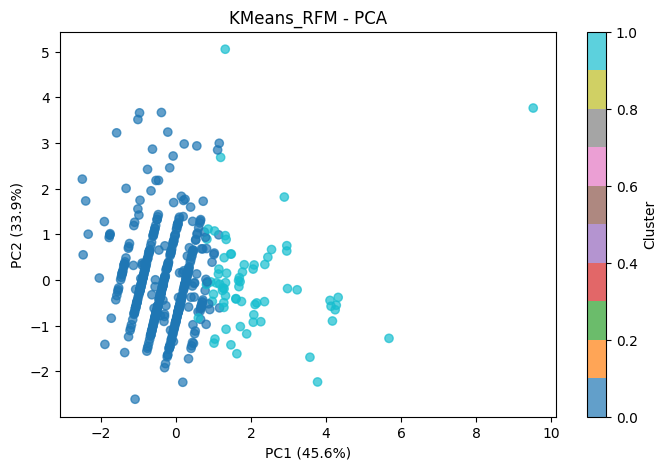

In [70]:
# RFM PCA visualisation
pca = PCA(n_components=2)
rfm_2d = pca.fit_transform(X_rfm)

print(
    "PCA explained variance:",
    pca.explained_variance_ratio_.round(3)
)

for solution in ['Ward_RFM', 'KMeans_RFM']:
    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        rfm_2d[:, 0],
        rfm_2d[:, 1],
        c=DATA[solution],
        cmap='tab10',
        alpha=0.7
    )

    plt.xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"
    )
    plt.ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"
    )
    plt.title(solution + ' - PCA')
    plt.colorbar(scatter, label='Cluster')
    plt.show()


In [71]:
# Algorithm comparison on identical shares
for name, ward_col, kmeans_col in [
    ('RiskReturn', 'Ward_Risk', 'KMeans_Risk'),
    ('RFM', 'Ward_RFM', 'KMeans_RFM')
]:
    print("\nAlgorithm comparison:", name)

    print(
        "Adjusted Rand Index:",
        round(
            adjusted_rand_score(
                DATA[ward_col], DATA[kmeans_col]
            ), 4
        )
    )

    display(pd.crosstab(
        DATA[ward_col],
        DATA[kmeans_col]
    ))



Algorithm comparison: RiskReturn
Adjusted Rand Index: 0.2097


KMeans_Risk,0,1
Ward_Risk,,
0,345,110
1,0,36



Algorithm comparison: RFM
Adjusted Rand Index: 0.7393


KMeans_RFM,0,1
Ward_RFM,,
0,397,2
1,25,67


Task 2.5 — RFM Sensitivity and Correlated Inputs

Task 2.5.1 — Correlation Analysis

In [72]:
rfm_correlation = FEATURES[
    ['R', 'F', 'LogM']
].corr(method='pearson')

print("Correlation between R, F and log1p(M):")
display(rfm_correlation.round(3))


Correlation between R, F and log1p(M):


,R,F,LogM
R,1.000,-0.342,0.159
F,-0.342,1.000,0.022
LogM,0.159,0.022,1.000


Task 2.5.2 — Removal of Monetary

In [73]:
# Re-standardise Recency and Frequency
X_rf = StandardScaler().fit_transform(
    FEATURES[['R', 'F']]
)

In [74]:
# Use the same number of Ward RFM clusters
k = ward_k['RFM']

rf_without_m = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward',
    metric='euclidean'
).fit_predict(X_rf)

In [75]:
# Adjusted Rand Index
ari = adjusted_rand_score(
    MODEL_LABELS['Ward_RFM'],
    rf_without_m
)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.9523


In [76]:
# Cluster membership comparison
comparison = pd.crosstab(
    MODEL_LABELS['Ward_RFM'],
    rf_without_m,
    rownames=['Original RFM Cluster'],
    colnames=['RF Cluster Without M']
)

print("Cluster Membership Comparison:")
display(comparison)

Cluster Membership Comparison:


RF Cluster Without M,0,1
Original RFM Cluster,,
0,397,2
1,3,89


In [77]:
# Compare original and reduced cluster profiles
comparison_data = FEATURES[['R', 'F', 'M']].copy()

comparison_data['Original_RFM'] = (
    MODEL_LABELS['Ward_RFM']
)

comparison_data['Without_M'] = rf_without_m

for solution in ['Original_RFM', 'Without_M']:
    print("\nCluster Profile:", solution)

    profile = comparison_data.groupby(solution).agg(
        Shares=('M', 'size'),
        MeanR=('R', 'mean'),
        MeanF=('F', 'mean'),
        MeanM_USD=('M', 'mean'),
        MedianM_USD=('M', 'median')
    )

    display(profile.round(3))



Cluster Profile: Original_RFM


,Shares,MeanR,MeanF,MeanM_USD,MedianM_USD
Original_RFM,,,,,
0,399,12.328,3.211,3.835661e+10,1.548218e+10
1,92,55.587,2.054,4.569727e+10,2.048974e+10



Cluster Profile: Without_M


,Shares,MeanR,MeanF,MeanM_USD,MedianM_USD
Without_M,,,,,
0,400,12.320,3.212,3.782930e+10,1.546039e+10
1,91,56.099,2.033,4.809577e+10,2.084781e+10


Task 3: Business Intelligence and Critical Review

3.2.1 Cluster profiles and sector composition

In [78]:
from sklearn.metrics import adjusted_rand_score

# Combine the original features with Task 2 cluster assignments
assignments = FEATURES[
    ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']
].join(MODEL_LABELS)

# Add GICS sector information for each share
sector_map = (
    constituents.drop_duplicates('YahooTicker')
    .set_index('YahooTicker')['GICS Sector']
)

assignments['GICS Sector'] = (
    sector_map.reindex(assignments.index).fillna('Unknown')
)

assignments['MeanReturnPct'] = (
    assignments['MeanWeeklyReturn'] * 100
)

In [79]:
# Define the four clustering solutions
model_names = {
    'Ward_Risk': 'Ward risk/return',
    'Ward_RFM': 'Ward RFM',
    'KMeans_Risk': 'K-means risk/return',
    'KMeans_RFM': 'K-means RFM'
}

# Compare cluster profiles in original units
profiles = {}

for model_col in model_names:
    profiles[model_col] = assignments.groupby(model_col).agg(
        Shares=('M', 'size'),
        MeanReturnPct=('MeanReturnPct', 'mean'),
        MeanBeta=('WeeklyBeta', 'mean'),
        MeanRecency=('R', 'mean'),
        MeanFrequency=('F', 'mean'),
        MeanMonetaryUSD=('M', 'mean')
    )

cluster_profiles = pd.concat(
    profiles, names=['Solution', 'Cluster']
)

print('Cluster profiles in original units:')
display(cluster_profiles.round(3))


Cluster profiles in original units:


Shares  MeanReturnPct  MeanBeta  MeanRecency  \
Solution    Cluster                                                 
Ward_Risk   0           455          0.241     0.938       19.835   
            1            36          0.902     1.519       28.000   
Ward_RFM    0           399          0.289     0.974       12.328   
            1            92          0.293     1.009       55.587   
KMeans_Risk 0           345          0.183     0.818       19.458   
            1           146          0.541     1.366       22.740   
KMeans_RFM  0           422          0.287     0.976       13.450   
            1            69          0.308     1.012       63.145   

                     MeanFrequency  MeanMonetaryUSD  
Solution    Cluster                                  
Ward_Risk   0                2.967     3.422715e+10  
            1                3.333     1.093078e+11  
Ward_RFM    0                3.211     3.835661e+10  
            1                2.054     4.569727e+10  
KMeans_Risk 0                2.922     2.183804e+10  
            1                3.164     8.201583e+10  
KMeans_RFM  0                3.187     3.271447e+10  
            1                1.812     8.265111e+10

In [80]:
# Calculate sector counts and within-cluster percentages
sector_counts = {}

for model_col in model_names:
    counts = pd.crosstab(
        assignments[model_col],
        assignments['GICS Sector']
    )

    sector_counts[model_col] = counts

sector_counts = pd.concat(
    sector_counts, names=['Solution', 'Cluster']
).fillna(0).astype(int)

sector_percent = sector_counts.div(
    sector_counts.sum(axis=1), axis=0
).mul(100)

print('Sector counts:')
display(sector_counts)

print('Sector share within each cluster (%):')
display(sector_percent.round(1))


Sector counts:


GICS Sector          Communication Services  Consumer Discretionary  \
Solution    Cluster                                                   
Ward_Risk   0                            20                      43   
            1                             1                       4   
Ward_RFM    0                            17                      37   
            1                             4                      10   
KMeans_Risk 0                            15                      24   
            1                             6                      23   
KMeans_RFM  0                            19                      39   
            1                             2                       8   

GICS Sector          Consumer Staples  Energy  Financials  Health Care  \
Solution    Cluster                                                      
Ward_Risk   0                      32      17          70           57   
            1                       0       4           5            1   
Ward_RFM    0                      24      19          62           49   
            1                       8       2          13            9   
KMeans_Risk 0                      31      11          57           56   
            1                       1      10          18            2   
KMeans_RFM  0                      27      20          64           50   
            1                       5       1          11            8   

GICS Sector          Industrials  Information Technology  Materials  \
Solution    Cluster                                                   
Ward_Risk   0                 72                      63         23   
            1                  7                      11          1   
Ward_RFM    0                 70                      54         16   
            1                  9                      20          8   
KMeans_Risk 0                 50                      26         20   
            1                 29                      48          4   
KMeans_RFM  0                 74                      60         18   
            1                  5                      14          6   

GICS Sector          Real Estate  Utilities  
Solution    Cluster                          
Ward_Risk   0                 29         29  
            1                  1          1  
Ward_RFM    0                 30         21  
            1                  0          9  
KMeans_Risk 0                 27         28  
            1                  3          2  
KMeans_RFM  0                 30         21  
            1                  0          9

Sector share within each cluster (%):


GICS Sector          Communication Services  Consumer Discretionary  \
Solution    Cluster                                                   
Ward_Risk   0                           4.4                     9.5   
            1                           2.8                    11.1   
Ward_RFM    0                           4.3                     9.3   
            1                           4.3                    10.9   
KMeans_Risk 0                           4.3                     7.0   
            1                           4.1                    15.8   
KMeans_RFM  0                           4.5                     9.2   
            1                           2.9                    11.6   

GICS Sector          Consumer Staples  Energy  Financials  Health Care  \
Solution    Cluster                                                      
Ward_Risk   0                     7.0     3.7        15.4         12.5   
            1                     0.0    11.1        13.9          2.8   
Ward_RFM    0                     6.0     4.8        15.5         12.3   
            1                     8.7     2.2        14.1          9.8   
KMeans_Risk 0                     9.0     3.2        16.5         16.2   
            1                     0.7     6.8        12.3          1.4   
KMeans_RFM  0                     6.4     4.7        15.2         11.8   
            1                     7.2     1.4        15.9         11.6   

GICS Sector          Industrials  Information Technology  Materials  \
Solution    Cluster                                                   
Ward_Risk   0               15.8                    13.8        5.1   
            1               19.4                    30.6        2.8   
Ward_RFM    0               17.5                    13.5        4.0   
            1                9.8                    21.7        8.7   
KMeans_Risk 0               14.5                     7.5        5.8   
            1               19.9                    32.9        2.7   
KMeans_RFM  0               17.5                    14.2        4.3   
            1                7.2                    20.3        8.7   

GICS Sector          Real Estate  Utilities  
Solution    Cluster                          
Ward_Risk   0                6.4        6.4  
            1                2.8        2.8  
Ward_RFM    0                7.5        5.3  
            1                0.0        9.8  
KMeans_Risk 0                7.8        8.1  
            1                2.1        1.4  
KMeans_RFM  0                7.1        5.0  
            1                0.0       13.0

In [81]:
# Label groups using beta or Recency
def row_label(model_col, k):
    is_risk = model_col.lower().endswith('risk')

    medians = assignments.groupby(model_col)[
        'WeeklyBeta' if is_risk else 'R'
    ].median()

    if len(medians) == 2:
        higher = (k == medians.idxmax())

        label = (
            ('higher beta' if higher else 'lower beta')
            if is_risk
            else ('less recent' if higher else 'more recent')
        )
    else:
        label = (
            f'beta {medians.loc[k]:.2f}'
            if is_risk
            else f'Recency {medians.loc[k]:.0f} days'
        )

    size = int((assignments[model_col] == k).sum())

    return f'{model_names[model_col]} - {label} (n={size})'


Text(0.5, 1.0, 'Sector Share of Each Cluster (%)')

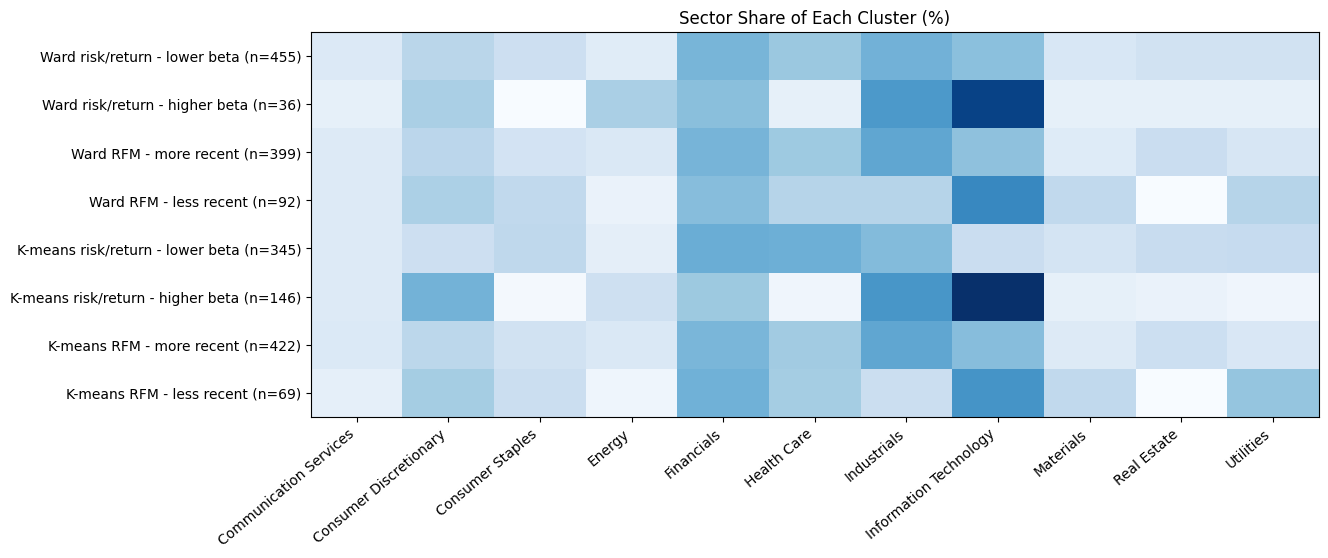

In [82]:
# Create the sector percentage heatmap
fig, ax = plt.subplots(
    figsize=(13, max(5, len(sector_percent) * 0.6))
)

image = ax.imshow(
    sector_percent.to_numpy(),
    cmap='Blues',
    vmin=0,
    aspect='auto'
)

ax.set_xticks(range(len(sector_percent.columns)))
ax.set_xticklabels(
    sector_percent.columns,
    rotation=40,
    ha='right'
)

ax.set_yticks(range(len(sector_percent)))
ax.set_yticklabels([
    row_label(model, cluster)
    for model, cluster in sector_percent.index
])

ax.set_title('Sector Share of Each Cluster (%)')


In [83]:
# Display sector percentages inside heatmap cells
max_value = sector_percent.to_numpy().max()

for row, values in enumerate(sector_percent.to_numpy()):
    for col, value in enumerate(values):
        ax.text(
            col, row, f'{value:.0f}',
            ha='center',
            va='center',
            fontsize=9,
            color='white' if value > max_value * 0.6
            else '#132f46'
        )

fig.colorbar(
    image,
    ax=ax,
    label='Shares in sector (%)',
    shrink=0.8
)

plt.tight_layout()
fig.savefig(
    OUTPUT / 'cluster_sectors.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()


<Figure size 640x480 with 0 Axes>

In [84]:
# Compare Ward risk-return and Ward RFM memberships
cross_view = pd.crosstab(
    assignments['Ward_Risk'],
    assignments['Ward_RFM'],
    rownames=['Ward Risk Cluster'],
    colnames=['Ward RFM Cluster']
)

cross_ari = adjusted_rand_score(
    assignments['Ward_Risk'],
    assignments['Ward_RFM']
)

print('Ward Risk vs Ward RFM Membership Comparison:')
display(cross_view)

print('Adjusted Rand Index:', round(cross_ari, 4))


Ward Risk vs Ward RFM Membership Comparison:


Ward RFM Cluster,0,1
Ward Risk Cluster,,
0,372,83
1,27,9


Adjusted Rand Index: 0.0274


In [85]:
# Save the results
cluster_profiles.to_csv(
    OUTPUT / 'task3_cluster_profiles.csv'
)

sector_counts.to_csv(
    OUTPUT / 'sector_counts.csv'
)

sector_percent.to_csv(
    OUTPUT / 'sector_percent_within_cluster.csv'
)

cross_view.to_csv(
    OUTPUT / 'risk_vs_activity_membership.csv'
)